## Carregamento do dataset SSVEP

Para o projeto, trabalhamos com o paradigma **SSVEP** (*Steady-State Visual Evoked Potential*), utilizando a base pública de **Nakanishi et al. (2015)** [1].

Este dataset possui **10 participantes**. Primeiro será carregada a base de um deles para entender a estrutura; depois, todos.

A aplicação é um **soletrador de 12 alvos** em grade 4×3 (como o teclado de um telefone). Cada alvo pisca numa frequência diferente, de **9,25 a 14,75 Hz** (passo de 0,5 Hz), com fase própria (passo de 0,5π), técnica chamada JFPM. Em cada tentativa, um alvo é indicado por 1 s e depois todos piscam por **4 s** enquanto a pessoa olha para o indicado. São **15 blocos**, cada um com uma tentativa por alvo.

O equipamento utilizado foi o **BioSemi ActiveTwo**, com **8 eletrodos na região occipital**, gravado a 2048 Hz e disponibilizado a **256 Hz**.

[1] M. Nakanishi, Y. Wang, Y.-T. Wang, T.-P. Jung. *A Comparison Study of Canonical Correlation Analysis Based Methods for Detecting Steady-State Visual Evoked Potentials*. PLoS ONE 10(10): e0140703, 2015. Dados: https://github.com/mnakanishi/12JFPM_SSVEP

In [1]:
# Carregamento do dataset para o participante 1

from scipy.io import loadmat
import numpy as np

raw_data = loadmat('dados/s1.mat')
raw_data.keys()

dict_keys(['__header__', '__version__', '__globals__', 'ans', 'train', 'list_sub', 'sub_i', 'eeg'])

In [2]:
# Shape de cada variável presente no arquivo

for k, v in raw_data.items():
    if not k.startswith('__'):
        print(f'{k:10s} {v.shape}')

ans        (1, 4)
train      (12, 18, 1114, 15)
list_sub   (1, 10)
sub_i      (1, 1)
eeg        (12, 8, 1114, 15)


A variável principal é **`eeg`**. As outras são sobras do MATLAB de quando o autor salvou o arquivo (`ans` guarda um shape, `sub_i` o número do sujeito, `list_sub` uma lista de índices, e `train` contém os mesmos 8 canais de `eeg` mais 10 canais extras que não são usados). Seguimos o README da base e usamos só `eeg`.

In [3]:
# Informações básicas do dataset
# (o arquivo não traz taxa de amostragem nem nomes de canais: vêm do README / artigo)

fs = 256
freqs = [9.25, 11.25, 13.25, 9.75, 11.75, 13.75, 10.25, 12.25, 14.25, 10.75, 12.75, 14.75]
teclas = list(' adeilmnorsu')   # caractere associado a cada alvo no nosso soletrador

eeg = raw_data['eeg']
n_alvos, n_canais, n_amostras, n_tentativas = eeg.shape

print(f'Taxa de amostragem: {fs} Hz')
print(f'Número de canais: {n_canais} (região occipital)')
print(f'Número de alvos: {n_alvos}')
print(f'Amostras por tentativa: {n_amostras} ({n_amostras / fs:.2f} s)')
print(f'Tentativas por alvo: {n_tentativas}')
print('\nAlvo -> caractere -> frequência:')
for i, (c, f) in enumerate(zip(teclas, freqs)):
    print(f'  {i:2d} -> {repr(c)} -> {f} Hz')

Taxa de amostragem: 256 Hz
Número de canais: 8 (região occipital)
Número de alvos: 12
Amostras por tentativa: 1114 (4.35 s)
Tentativas por alvo: 15

Alvo -> caractere -> frequência:
   0 -> ' ' -> 9.25 Hz
   1 -> 'a' -> 11.25 Hz
   2 -> 'd' -> 13.25 Hz
   3 -> 'e' -> 9.75 Hz
   4 -> 'i' -> 11.75 Hz
   5 -> 'l' -> 13.75 Hz
   6 -> 'm' -> 10.25 Hz
   7 -> 'n' -> 12.25 Hz
   8 -> 'o' -> 14.25 Hz
   9 -> 'r' -> 10.75 Hz
  10 -> 's' -> 12.75 Hz
  11 -> 'u' -> 14.75 Hz


In [4]:
# Shape da matriz principal

print('eeg:', eeg.shape, '-> (alvos, canais, amostras, tentativas)')

eeg: (12, 8, 1114, 15) -> (alvos, canais, amostras, tentativas)


In [5]:
# Exemplo de dados brutos: alvo 8 ('o', 14,25 Hz), canal 1, tentativa 1
# Os valores são grandes por causa do offset (nível DC) do aparelho; o filtro remove isso.

print(eeg[8, 0, :10, 0])

[13756.78125 13757.53125 13755.5     13754.9375  13745.      13740.40625
 13739.3125  13747.59375 13748.09375 13749.125  ]


### Organização das informações da base de dados

Assim como no exemplo da disciplina, os dados são reorganizados em uma única estrutura **X** no formato `(n_tentativas, n_amostras, n_canais)` e um vetor de rótulos **y** com o alvo de cada tentativa.

Diferente do P300, aqui **não é preciso segmentar por flash**: o arquivo já vem com cada tentativa recortada e com o mesmo tamanho (1114 amostras), então basta reordenar os eixos.

In [6]:
# Reorganizando para (n_tentativas, n_amostras, n_canais)
# eixo original: (alvos, canais, amostras, tentativas) -> (tentativas, alvos, amostras, canais)

data_X = eeg.transpose(3, 0, 2, 1).reshape(-1, n_amostras, n_canais)
data_y = np.tile(np.arange(n_alvos), n_tentativas)        # alvo de cada tentativa

print('Formato de data_X:', data_X.shape)
print('Formato de data_y:', data_y.shape)
print('Primeiros rótulos:', data_y[:24])

Formato de data_X: (180, 1114, 8)
Formato de data_y: (180,)
Primeiros rótulos: [ 0  1  2  3  4  5  6  7  8  9 10 11  0  1  2  3  4  5  6  7  8  9 10 11]


In [7]:
# Conferindo que a reorganização não embaralhou nada:
# a tentativa 0 de data_X deve ser o alvo 0, repetição 0, do eeg original

print(np.allclose(data_X[0], eeg[0, :, :, 0].T))
print(np.allclose(data_X[13], eeg[1, :, :, 1].T))   # tentativa 13 = alvo 1, repetição 2

True
True


### Recorte do período de estímulo

Cada tentativa tem 0,15 s antes do início do estímulo (amostra 39). Somamos ainda 0,135 s de latência visual (tempo para o cérebro começar a responder), como no artigo original, e ficamos com 4 s de estímulo (1024 amostras).

In [8]:
inicio = 39 + int(round(0.135 * fs))   # = 74
janela = 4 * fs                         # 4 s = 1024 amostras

data_X_estim = data_X[:, inicio:inicio + janela, :]
print('Início do recorte (amostra):', inicio)
print('Formato após o recorte:', data_X_estim.shape)

Início do recorte (amostra): 74
Formato após o recorte: (180, 1024, 8)


### Todos os participantes

In [9]:
# Carregando os 10 participantes no mesmo formato

X_todos, y_todos, sujeito = [], [], []
for s in range(1, 11):
    e = loadmat(f'dados/s{s}.mat')['eeg']
    X_s = e.transpose(3, 0, 2, 1).reshape(-1, e.shape[2], e.shape[1])[:, inicio:inicio + janela, :]
    X_todos.append(X_s)
    y_todos.append(np.tile(np.arange(e.shape[0]), e.shape[3]))
    sujeito.append(np.full(len(X_s), s))

X_todos = np.concatenate(X_todos)
y_todos = np.concatenate(y_todos)
sujeito = np.concatenate(sujeito)

print('X_todos:', X_todos.shape)
print('y_todos:', y_todos.shape)
print('sujeito:', sujeito.shape)
print('Tentativas por alvo:', np.bincount(y_todos))

X_todos: (1800, 1024, 8)
y_todos: (1800,)
sujeito: (1800,)
Tentativas por alvo: [150 150 150 150 150 150 150 150 150 150 150 150]


### Divisão treino / teste

A base não vem dividida. A divisão é feita **por participante**, para testar em pessoas que a rede nunca viu: participantes 1–8 para treino e 9–10 para teste.

In [10]:
treino = sujeito <= 8
teste = sujeito >= 9

X_treino, y_treino = X_todos[treino], y_todos[treino]
X_teste, y_teste = X_todos[teste], y_todos[teste]

print('X_treino:', X_treino.shape, '| y_treino:', y_treino.shape)
print('X_teste: ', X_teste.shape, '| y_teste: ', y_teste.shape)

X_treino: (1440, 1024, 8) | y_treino: (1440,)
X_teste:  (360, 1024, 8) | y_teste:  (360,)


### Visualização: sinal bruto, filtrado e espectro

Para conferir que o SSVEP está nos dados: filtramos 6–80 Hz e calculamos a FFT. O espectro deve ter um pico na frequência do alvo olhado. Usamos o participante 9 (de teste) e o alvo 'o' (14,25 Hz).

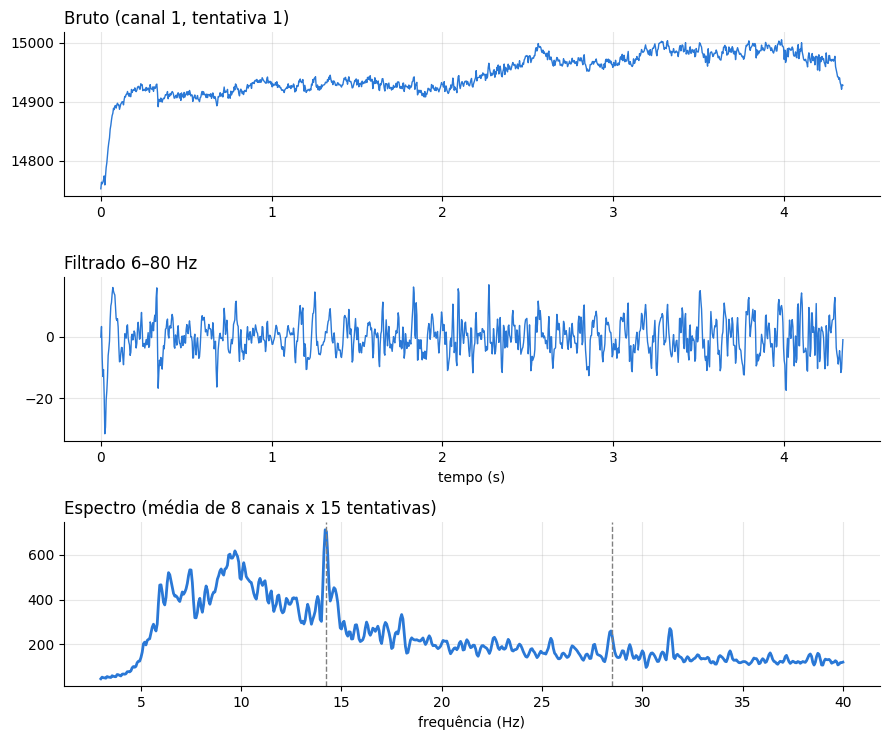

Pico do espectro: 14.19 Hz (esperado: 14.25 Hz)


In [11]:
from scipy.signal import cheby1, filtfilt
import matplotlib.pyplot as plt

alvo = 8                                       # 'o', 14,25 Hz
e9 = loadmat('dados/s9.mat')['eeg']
b, a = cheby1(4, 0.5, [6 / (fs / 2), 80 / (fs / 2)], btype='band')
filtrado = filtfilt(b, a, e9[alvo], axis=1)    # (canais, amostras, tentativas)

seg = filtrado[:, inicio:inicio + janela, :]
amp = np.abs(np.fft.rfft(seg, n=4096, axis=1)).mean(axis=(0, 2))
fr = np.fft.rfftfreq(4096, 1 / fs)
sel = (fr >= 3) & (fr <= 40)

t = np.arange(e9.shape[2]) / fs
fig, ax = plt.subplots(3, 1, figsize=(9, 7.5))
ax[0].plot(t, e9[alvo, 0, :, 0], color='#2a78d6', lw=1); ax[0].set_title('Bruto (canal 1, tentativa 1)', loc='left')
ax[1].plot(t, filtrado[0, :, 0], color='#2a78d6', lw=1); ax[1].set_title('Filtrado 6–80 Hz', loc='left'); ax[1].set_xlabel('tempo (s)')
ax[2].plot(fr[sel], amp[sel], color='#2a78d6', lw=2); ax[2].set_title('Espectro (média de 8 canais x 15 tentativas)', loc='left')
for h in (1, 2):
    ax[2].axvline(h * freqs[alvo], color='gray', ls='--', lw=1)
ax[2].set_xlabel('frequência (Hz)')
for x in ax:
    x.spines[['top', 'right']].set_visible(False); x.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f'Pico do espectro: {fr[sel][np.argmax(amp[sel])]:.2f} Hz (esperado: {freqs[alvo]} Hz)')

In [12]:
# salvamento dos dados em numpy arrays

# np.save('X_todos.npy', X_todos)
# np.save('y_todos.npy', y_todos)
# np.save('sujeito.npy', sujeito)